# Importing Necessary Libraries

In [48]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report
import re
import string
from sklearn.metrics import precision_score,recall_score,f1_score

In [2]:
import warnings
warnings.filterwarnings('ignore')

# Reading Data

In [3]:
data = pd.read_csv("train.csv")

# Head

In [4]:
data.head()

,id,title,author,text,label
0,0,House Dem Aide: We Didn’t Even See Comey’s Let...,Darrell Lucus,House Dem Aide: We Didn’t Even See Comey’s Let...,1
1,1,"FLYNN: Hillary Clinton, Big Woman on Campus - ...",Daniel J. Flynn,Ever get the feeling your life circles the rou...,0
2,2,Why the Truth Might Get You Fired,Consortiumnews.com,"Why the Truth Might Get You Fired October 29, ...",1
3,3,15 Civilians Killed In Single US Airstrike Hav...,Jessica Purkiss,Videos 15 Civilians Killed In Single US Airstr...,1
4,4,Iranian woman jailed for fictional unpublished...,Howard Portnoy,Print \nAn Iranian woman has been sentenced to...,1


# Tail

In [5]:
data.tail()

,id,title,author,text,label
20795,20795,Rapper T.I.: Trump a ’Poster Child For White S...,Jerome Hudson,Rapper T. I. unloaded on black celebrities who...,0
20796,20796,"N.F.L. Playoffs: Schedule, Matchups and Odds -...",Benjamin Hoffman,When the Green Bay Packers lost to the Washing...,0
20797,20797,Macy’s Is Said to Receive Takeover Approach by...,Michael J. de la Merced and Rachel Abrams,The Macy’s of today grew from the union of sev...,0
20798,20798,"NATO, Russia To Hold Parallel Exercises In Bal...",Alex Ansary,"NATO, Russia To Hold Parallel Exercises In Bal...",1
20799,20799,What Keeps the F-35 Alive,David Swanson,"David Swanson is an author, activist, journa...",1


# About the Dataset

id: unique id for a news article

title: the title of a news article

author: author of the news article

text: the text of the article; could be incomplete

label: a label that marks whether the news article is real or fake:

0: Fake News
1: Real News

# Column Names

In [6]:
data.columns

Index(['id', 'title', 'author', 'text', 'label'], dtype='object')

# Info 

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20800 entries, 0 to 20799
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      20800 non-null  int64 
 1   title   20242 non-null  object
 2   author  18843 non-null  object
 3   text    20761 non-null  object
 4   label   20800 non-null  int64 
dtypes: int64(2), object(3)
memory usage: 812.6+ KB


# Datatypes 

In [8]:
data.dtypes

id         int64
title     object
author    object
text      object
label      int64
dtype: object

# Descriptive Stats

In [9]:
data.describe()

,id,label
count,20800.000000,20800.000000
mean,10399.500000,0.500625
std,6004.587135,0.500012
min,0.000000,0.000000
25%,5199.750000,0.000000
50%,10399.500000,1.000000
75%,15599.250000,1.000000
max,20799.000000,1.000000


In [12]:
data.describe(include='object')

,title,author,text
count,20242,18843,20761
unique,19803,4201,20386
top,Get Ready For Civil Unrest: Survey Finds That ...,Pam Key,
freq,5,243,75


# Unique Values

In [13]:
data['label'].value_counts()

1    10413
0    10387
Name: label, dtype: int64

# Preprocessing

Handling Missing Values

In [19]:
data.isnull().sum()

id           0
title      558
author    1957
text        39
label        0
dtype: int64

In [20]:
data = data.fillna(' ')

In [21]:
data.isnull().sum()

id        0
title     0
author    0
text      0
label     0
dtype: int64

# Duplicate Detection

In [22]:
import pandas as pd
duplicates = data[data.duplicated()]
specific_duplicates = data[data.duplicated(subset=['text', 'label'])]

print("All duplicates:")
print(duplicates)

print("\nSpecific duplicates:")
print(specific_duplicates)


All duplicates:
Empty DataFrame
Columns: [id, title, author, text, label]
Index: []

Specific duplicates:
          id                                              title  \
142      142  Gorafi Magazine : Entretien exclusif avec Bara...   
169      169  Mohamad Khweis: Another “Virginia Man” (Palest...   
295      295  A Connecticut Reader Reports Record Voter Regi...   
470      470  BULLETIN: There ARE Righteous Jews For Trump!;...   
480      480  Watch: Muslim ‘Palestinians’ Declare “We follo...   
...      ...                                                ...   
20728  20728  Trump warns of World War III if Clinton is ele...   
20749  20749  Realities Faced by Black Canadians are a Natio...   
20750  20750              Why Did Four Googles Kill This White?   
20754  20754                     No More American Thanksgivings   
20769  20769       WORLD WAR 3 ▲ Mr.President #004 ▲ xFrozenLPx   

                 author                                               text  \
142        

In [23]:
import pandas as pd
data.duplicated()  # Returns a boolean Series indicating duplicate rows
data[data.duplicated()]  # Returns the duplicated rows

,id,title,author,text,label


In [24]:
data.duplicated().any()

False

# Shuffling the rows randomly

In [25]:
data = data.sample(frac = 1)

In [26]:
data.head()

,id,title,author,text,label
13910,13910,Hacker Guccifer 2.0 Says Election Could Be Rig...,,Pin \n( ZHE ) Before the recent torrent of dai...,1
7269,7269,WATCH: Hillary Aide RUSHES to Her Side to Help...,Chris Menahan,"Posted on October 27, 2016 by Chris Menahan \n...",1
14582,14582,DONALD TRUMP HAS WON THE 2016 PRESIDENTIAL ELE...,IWB,It only takes a few moments to share an articl...,1
2929,2929,Capitol Hill Source: Intel Chair Nunes Tempora...,Neil W. McCabe,A Capitol Hill source familiar with the chairm...,0
14992,14992,Talent Agency WME-IMG Forming PAC for Trump Er...,Jerome Hudson,Hollywood talent agency (William Morris En...,0


In [27]:
data.reset_index(inplace = True)
data.drop(['index'], axis = 1, inplace = True)

# Outlier Detection 

<AxesSubplot:xlabel='label'>

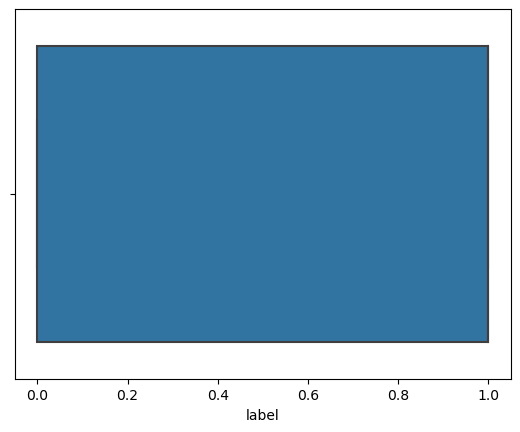

In [28]:
sns.boxplot(x=data['label'], data=data)

IQR

In [29]:
Q1=data.quantile(0.25)
Q3=data.quantile(0.75)
IQR=Q3-Q1

In [30]:
IQR

id       10399.5
label        1.0
dtype: float64

In [31]:
((data<(Q1-1.5*IQR))| (data>(Q3+1.5*IQR))).sum()

author    0
id        0
label     0
text      0
title     0
dtype: int64

# Dropping Columns That Are Not Required

In [32]:
data.columns

Index(['id', 'title', 'author', 'text', 'label'], dtype='object')

In [33]:
data = data.drop(['id', 'title', 'author'], axis = 1)

In [34]:
data.head()

,text,label
0,Pin \n( ZHE ) Before the recent torrent of dai...,1
1,"Posted on October 27, 2016 by Chris Menahan \n...",1
2,It only takes a few moments to share an articl...,1
3,A Capitol Hill source familiar with the chairm...,0
4,Hollywood talent agency (William Morris En...,0


# Text Preprocessing

In [35]:
data['text'] = data['text'].astype(str)

def wordopt(text):
    text = text.lower()
    text = re.sub('\[.*?\]','', text)
    text = re.sub("\\W", " ", text)
    text = re.sub('https?://\S+|www\.\S+', '', text)
    text = re.sub ('<.*?>+', '', text)
    text = re.sub('[%s]' % re.escape(string.punctuation), '', text)
    text = re.sub('\n', '', text)
    text = re.sub('\w*\d\w*', '', text)
    return text

In [36]:
data['text'] = data['text'].apply(wordopt)

# Visualization

# Pie Chart for label

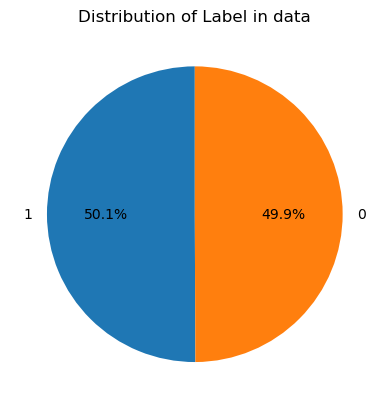

1    10413
0    10387
Name: label, dtype: int64


In [116]:
value_counts = data['label'].value_counts()
plt.pie(value_counts, labels=value_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Distribution of Label in data')
plt.show()
print(value_counts)

# Bar Chart for Label Distribution

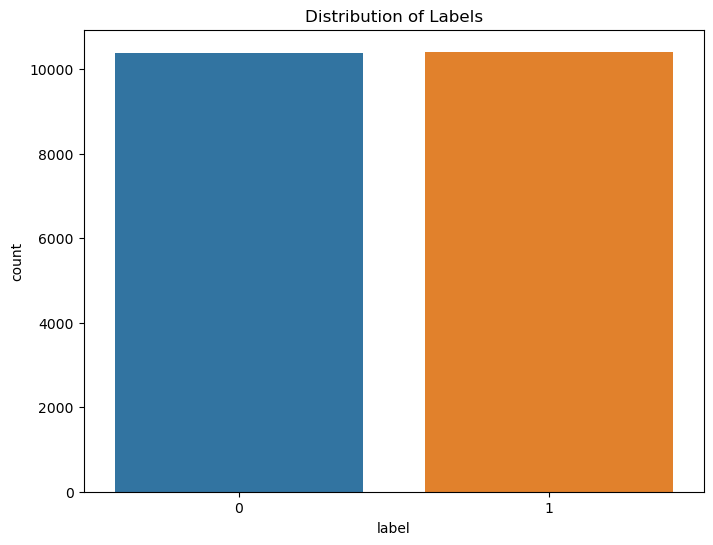

In [117]:
plt.figure(figsize=(8, 6))
sns.countplot(x='label', data=data)
plt.title('Distribution of Labels')
plt.show()

# Histogram for article length

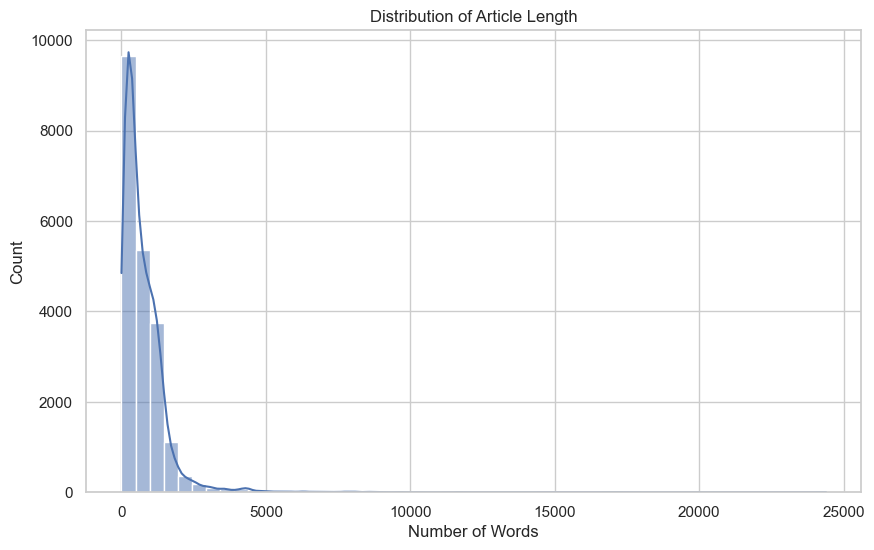

In [221]:
data['text_length'] = data['text'].apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 6))
sns.histplot(data['text_length'], bins=50, kde=True)
plt.title('Distribution of Article Length')
plt.xlabel('Number of Words')
plt.show()

# Word cloud for text content

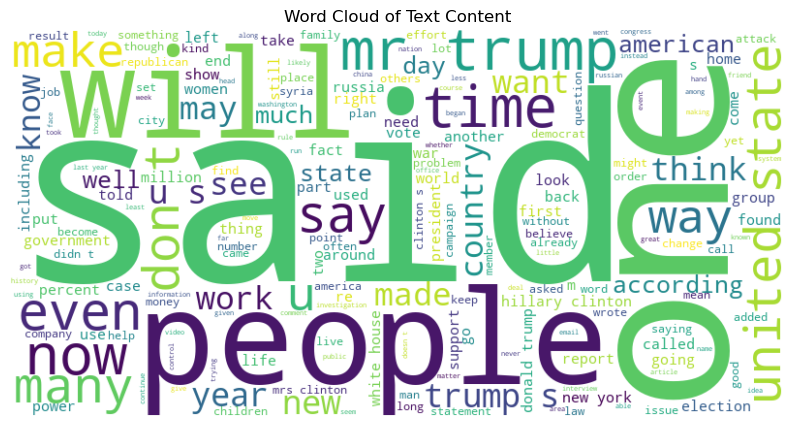

In [118]:
from wordcloud import WordCloud

wordcloud = WordCloud(width=800, height=400, background_color='white').generate(' '.join(data['text']))
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Text Content')
plt.show()

# Separating the Text and Label

In [37]:
x = data['text']
y = data['label']

# Splitting the dataset to training & test data

In [38]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25)

# Feature extraction using the TF-IDF (Term Frequency-Inverse Document Frequency) vectorization

In [39]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorization = TfidfVectorizer()
xv_train = vectorization.fit_transform(x_train)
xv_test = vectorization.transform(x_test)

# Logistic Regression

In [45]:
from sklearn.linear_model import LogisticRegression

LR = LogisticRegression()
LR.fit(xv_train, y_train)

LogisticRegression()

In [41]:
pred_lr = LR.predict(xv_test)

In [42]:
LR.score(xv_test, y_test)

0.9388461538461539

Confusion Matrix:
[[2409  163]
 [ 155 2473]]

True Negatives (TN): 2409
False Positives (FP): 163
False Negatives (FN): 155
True Positives (TP): 2473


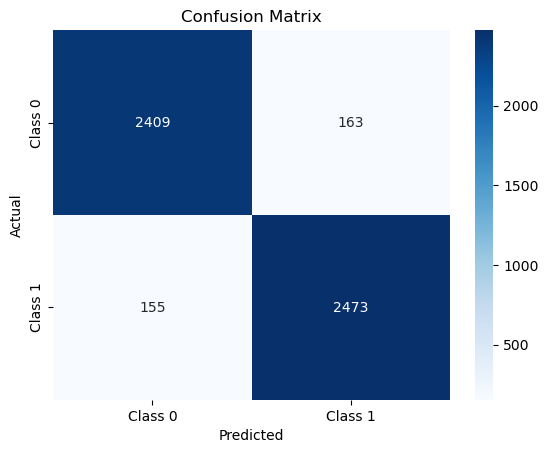

In [53]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, pred_lr)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), and True Positives (TP)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TP = conf_matrix[1, 1]

# Display results
print("Confusion Matrix:")
print(conf_matrix)
print("\nTrue Negatives (TN):", TN)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)
print("True Positives (TP):", TP)

# Visualize confusion matrix with seaborn heatmap
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report

In [54]:
print(classification_report(y_test, pred_lr))

              precision    recall  f1-score   support

           0       0.94      0.94      0.94      2572
           1       0.94      0.94      0.94      2628

    accuracy                           0.94      5200
   macro avg       0.94      0.94      0.94      5200
weighted avg       0.94      0.94      0.94      5200



# Precision

In [55]:
precision_score(y_test, pred_lr)

0.9381638846737481

# Sensitivity (Recall) - True Positive Rate

In [56]:
sensitivity = TP / (TP + FN)
print(f"Sensitivity (Recall): {sensitivity:.4f}")

Sensitivity (Recall): 0.9410


# F1 Score

In [58]:
f1_score(y_test, pred_lr)

0.9395896656534954

# Misclassification Rate

In [59]:
misclassification_rate = (FP + FN) / (TP + TN + FP + FN)
print(f"Misclassification Rate: {misclassification_rate:.4f}")

Misclassification Rate: 0.0612


# Specificity - True Negative Rate

In [60]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.9366


# Prevalence

In [61]:
prevalence = (TP + FN) / (TP + TN + FP + FN)
print(f"Prevalence: {prevalence:.4f}")

Prevalence: 0.5054


# False Positive Rate

In [62]:
false_positive_rate = FP / (TN + FP)
print(f"False Positive Rate: {false_positive_rate:.4f}")

False Positive Rate: 0.0634


# Decision Tree Classification

In [63]:
from sklearn.tree import DecisionTreeClassifier

DT = DecisionTreeClassifier()
DT.fit(xv_train, y_train)

DecisionTreeClassifier()

In [64]:
pred_dt = DT.predict(xv_test)

In [65]:
DT.score(xv_test, y_test)

0.8817307692307692

Confusion Matrix:
[[2265  307]
 [ 308 2320]]

True Negatives (TN): 2265
False Positives (FP): 307
False Negatives (FN): 308
True Positives (TP): 2320


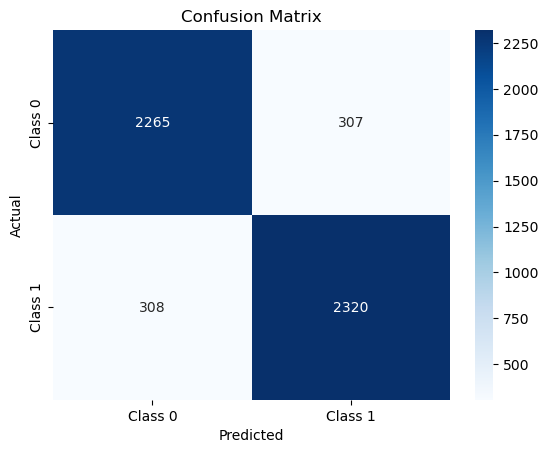

In [66]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, pred_dt)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), and True Positives (TP)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TP = conf_matrix[1, 1]

# Display results
print("Confusion Matrix:")
print(conf_matrix)
print("\nTrue Negatives (TN):", TN)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)
print("True Positives (TP):", TP)

# Visualize confusion matrix with seaborn heatmap
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report

In [68]:
print(classification_report(y_test, pred_dt))

              precision    recall  f1-score   support

           0       0.88      0.88      0.88      2572
           1       0.88      0.88      0.88      2628

    accuracy                           0.88      5200
   macro avg       0.88      0.88      0.88      5200
weighted avg       0.88      0.88      0.88      5200



# Precision

In [69]:
precision_score(y_test, pred_dt)

0.8831366577845451

# Sensitivity (Recall) - True Positive Rate

In [70]:
sensitivity = TP / (TP + FN)
print(f"Sensitivity (Recall): {sensitivity:.4f}")

Sensitivity (Recall): 0.8828


# F1 Score

In [71]:
f1_score(y_test, pred_dt)

0.8829686013320646

# Misclassification Rate

In [72]:
misclassification_rate = (FP + FN) / (TP + TN + FP + FN)
print(f"Misclassification Rate: {misclassification_rate:.4f}")

Misclassification Rate: 0.1183


# Specificity - True Negative Rate

In [73]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.8806


# Prevalence

In [74]:
prevalence = (TP + FN) / (TP + TN + FP + FN)
print(f"Prevalence: {prevalence:.4f}")

Prevalence: 0.5054


# False Positive Rate

In [75]:
false_positive_rate = FP / (TN + FP)
print(f"False Positive Rate: {false_positive_rate:.4f}")

False Positive Rate: 0.1194


# Support Vector Machine

In [76]:
from sklearn.svm import SVC

SVM = SVC(kernel='linear')
SVM.fit(xv_train, y_train)

SVC(kernel='linear')

In [77]:
pred_svm = SVM.predict(xv_test)

In [78]:
SVM.score(xv_test, y_test)

0.9601923076923077

Confusion Matrix:
[[2471  101]
 [ 106 2522]]

True Negatives (TN): 2471
False Positives (FP): 101
False Negatives (FN): 106
True Positives (TP): 2522


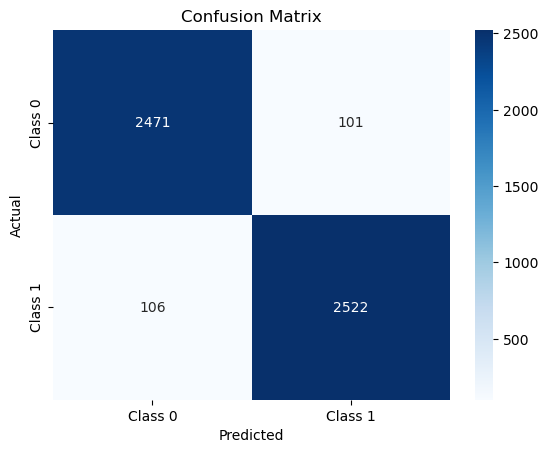

In [79]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, pred_svm)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), and True Positives (TP)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TP = conf_matrix[1, 1]

# Display results
print("Confusion Matrix:")
print(conf_matrix)
print("\nTrue Negatives (TN):", TN)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)
print("True Positives (TP):", TP)

# Visualize confusion matrix with seaborn heatmap
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report

In [80]:
print(classification_report(y_test, pred_svm))

              precision    recall  f1-score   support

           0       0.96      0.96      0.96      2572
           1       0.96      0.96      0.96      2628

    accuracy                           0.96      5200
   macro avg       0.96      0.96      0.96      5200
weighted avg       0.96      0.96      0.96      5200



# Precision

In [81]:
precision_score(y_test, pred_svm)

0.9614944719786505

# Sensitivity (Recall) - True Positive Rate

In [82]:
sensitivity = TP / (TP + FN)
print(f"Sensitivity (Recall): {sensitivity:.4f}")

Sensitivity (Recall): 0.9597


# F1 Score

In [83]:
f1_score(y_test, pred_svm)

0.9605789373452676

# Misclassification Rate

In [84]:
misclassification_rate = (FP + FN) / (TP + TN + FP + FN)
print(f"Misclassification Rate: {misclassification_rate:.4f}")

Misclassification Rate: 0.0398


# Specificity - True Negative Rate

In [85]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.9607


# Prevalence

In [86]:
prevalence = (TP + FN) / (TP + TN + FP + FN)
print(f"Prevalence: {prevalence:.4f}")

Prevalence: 0.5054


# False Positive Rate

In [87]:
false_positive_rate = FP / (TN + FP)
print(f"False Positive Rate: {false_positive_rate:.4f}")

False Positive Rate: 0.0393


# Random Forest

In [88]:
from sklearn.ensemble import RandomForestClassifier

RF = RandomForestClassifier(random_state = 0)
RF.fit(xv_train, y_train)

RandomForestClassifier(random_state=0)

In [89]:
pred_rf = RF.predict(xv_test)

In [90]:
RF.score(xv_test, y_test)

0.9115384615384615

Confusion Matrix:
[[2384  188]
 [ 272 2356]]

True Negatives (TN): 2384
False Positives (FP): 188
False Negatives (FN): 272
True Positives (TP): 2356


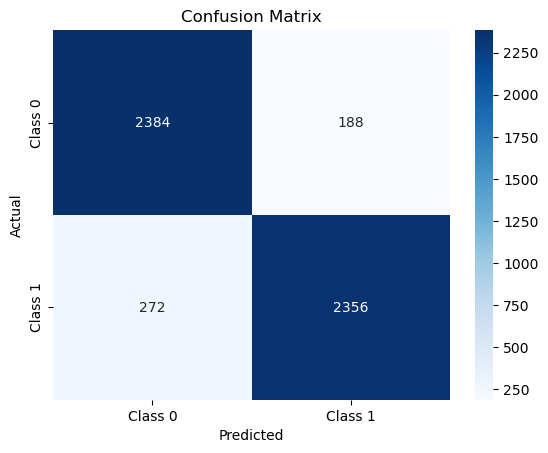

In [91]:
from sklearn.metrics import confusion_matrix

conf_matrix = confusion_matrix(y_test, pred_rf)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), and True Positives (TP)
TN = conf_matrix[0, 0]
FP = conf_matrix[0, 1]
FN = conf_matrix[1, 0]
TP = conf_matrix[1, 1]

# Display results
print("Confusion Matrix:")
print(conf_matrix)
print("\nTrue Negatives (TN):", TN)
print("False Positives (FP):", FP)
print("False Negatives (FN):", FN)
print("True Positives (TP):", TP)

# Visualize confusion matrix with seaborn heatmap
sns.heatmap(conf_matrix, annot=True, fmt="d", cmap="Blues", xticklabels=["Class 0", "Class 1"], yticklabels=["Class 0", "Class 1"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# Classification Report

In [92]:
print(classification_report(y_test, pred_rf))

              precision    recall  f1-score   support

           0       0.90      0.93      0.91      2572
           1       0.93      0.90      0.91      2628

    accuracy                           0.91      5200
   macro avg       0.91      0.91      0.91      5200
weighted avg       0.91      0.91      0.91      5200



# Precision

In [93]:
precision_score(y_test, pred_rf)

0.9261006289308176

# Sensitivity (Recall) - True Positive Rate

In [94]:
sensitivity = TP / (TP + FN)
print(f"Sensitivity (Recall): {sensitivity:.4f}")

Sensitivity (Recall): 0.8965


# F1 Score

In [95]:
f1_score(y_test, pred_svm)

0.9605789373452676

# Misclassification Rate

In [96]:
misclassification_rate = (FP + FN) / (TP + TN + FP + FN)
print(f"Misclassification Rate: {misclassification_rate:.4f}")

Misclassification Rate: 0.0885


# Specificity - True Negative Rate

In [97]:
specificity = TN / (TN + FP)
print(f"Specificity: {specificity:.4f}")

Specificity: 0.9269


# Prevalence

In [98]:
prevalence = (TP + FN) / (TP + TN + FP + FN)
print(f"Prevalence: {prevalence:.4f}")

Prevalence: 0.5054


# False Positive Rate

In [99]:
false_positive_rate = FP / (TN + FP)
print(f"False Positive Rate: {false_positive_rate:.4f}")

False Positive Rate: 0.0731


# Model Testing

In [109]:
def output_label(n):
    if n == 0:
        return "Fake News"
    elif n == 1:
        return "Authentic News"
    
def manual_testing(news):
    testing_news = {"text":[news]}
    new_def_test = pd.DataFrame(testing_news)
    new_def_test["text"] = new_def_test["text"].apply(wordopt)
    new_x_test = new_def_test["text"]
    new_xv_test = vectorization.transform(new_x_test)
    pred_LR = LR.predict(new_xv_test)
    pred_DT = DT.predict(new_xv_test)
    pred_SVM = SVM.predict(new_xv_test)
    pred_RF = RF.predict(new_xv_test)
    
    return print("\n\nLR Prediction: {} \nDT Prediction: {} \nSVM Prediction: {} \nRF Prediction: {} ".format(output_label(pred_LR[0]),
                                                                                                             output_label(pred_DT[0]),
                                                                                                              output_label(pred_SVM[0]),
                                                                                                              output_label(pred_RF[0])))


In [118]:
news = str(input())
manual_testing(news)

Poll: Russians Still Approve of Putin Most Russian survey respondents see the war in Ukraine as a broader conflict with the West and support it amid concerns about their own country’s economy.


LR Prediction: Authentic News 
DT Prediction: Authentic News 
SVM Prediction: Authentic News 
RF Prediction: Authentic News 
